In [1]:
import pandas as pd
from pathlib import Path

# Load all five yearly CSV files and concatenate them into one DataFrame
csv_files = sorted(Path('Data').glob('*.csv'))
frames = [pd.read_csv(file) for file in csv_files]
df = pd.concat(frames, ignore_index=True)

print('Columns:')
print(df.columns.tolist())
print('\nHead:')
display(df.head())

Columns:
['Unnamed: 0', 'Revenue', 'Revenue Growth', 'Cost of Revenue', 'Gross Profit', 'R&D Expenses', 'SG&A Expense', 'Operating Expenses', 'Operating Income', 'Interest Expense', 'Earnings before Tax', 'Income Tax Expense', 'Net Income - Non-Controlling int', 'Net Income - Discontinued ops', 'Net Income', 'Preferred Dividends', 'Net Income Com', 'EPS', 'EPS Diluted', 'Weighted Average Shs Out', 'Weighted Average Shs Out (Dil)', 'Dividend per Share', 'Gross Margin', 'EBITDA Margin', 'EBIT Margin', 'Profit Margin', 'Free Cash Flow margin', 'EBITDA', 'EBIT', 'Consolidated Income', 'Earnings Before Tax Margin', 'Net Profit Margin', 'Cash and cash equivalents', 'Short-term investments', 'Cash and short-term investments', 'Receivables', 'Inventories', 'Total current assets', 'Property, Plant & Equipment Net', 'Goodwill and Intangible Assets', 'Long-term investments', 'Tax assets', 'Total non-current assets', 'Total assets', 'Payables', 'Short-term debt', 'Total current liabilities', 'Long

,Unnamed: 0,Revenue,Revenue Growth,Cost of Revenue,Gross Profit,R&D Expenses,SG&A Expense,Operating Expenses,Operating Income,Interest Expense,...,Debt Growth,R&D Expense Growth,SG&A Expenses Growth,Sector,2015 PRICE VAR [%],Class,2016 PRICE VAR [%],2017 PRICE VAR [%],2018 PRICE VAR [%],2019 PRICE VAR [%]
0,PG,7.440100e+10,-0.0713,3.903000e+10,3.537100e+10,0.000000e+00,2.146100e+10,2.146100e+10,1.391000e+10,7.090000e+08,...,0.1228,0.0000,-0.1746,Consumer Defensive,-9.323276,0,NaN,NaN,NaN,NaN
1,VIPS,3.734148e+09,1.1737,2.805625e+09,9.285226e+08,1.083303e+08,3.441414e+08,7.939267e+08,1.345959e+08,1.214869e+07,...,NaN,1.6484,1.7313,Consumer Defensive,-25.512193,0,NaN,NaN,NaN,NaN
2,KR,9.837500e+10,0.0182,7.813800e+10,2.023700e+10,0.000000e+00,1.519600e+10,1.751200e+10,2.725000e+09,4.430000e+08,...,0.2738,0.0000,0.0234,Consumer Defensive,33.118297,1,NaN,NaN,NaN,NaN
3,RAD,2.552641e+10,0.0053,1.820268e+10,7.323734e+09,0.000000e+00,6.561162e+09,6.586482e+09,7.372520e+08,4.245910e+08,...,-0.0458,0.0000,-0.0060,Consumer Defensive,2.752291,1,NaN,NaN,NaN,NaN
4,GIS,1.790960e+10,0.0076,1.153980e+10,6.369800e+09,0.000000e+00,3.474300e+09,3.412400e+09,2.957400e+09,3.024000e+08,...,0.1025,0.0000,-0.0220,Consumer Defensive,12.897715,1,NaN,NaN,NaN,NaN


## Data Cleaning

This section handles missing values and one-hot encodes categorical variables without scaling, since the gradient boosting model will use the cleaned raw feature values.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate target from feature columns if needed
# The combined dataset includes the final target columns (2015-2019 price variance columns)
# For this preprocessing step, we will clean the whole feature matrix before modeling.
X = df.copy()

# Identify categorical columns
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Create preprocessing pipeline for numeric and categorical columns
numeric_cols = [col for col in X.columns if col not in categorical_cols]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

X_clean = preprocessor.fit_transform(X)

print('Shape after preprocessing:', X_clean.shape)
print('Feature matrix type:', type(X_clean))
print('Sample transformed values:')
print(X_clean[:2])

Shape after preprocessing: (22077, 5218)
Feature matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Sample transformed values:
  (0, 0)	74401000000.0
  (0, 1)	-0.0713
  (0, 2)	39030000000.0
  (0, 3)	35371000000.0
  (0, 5)	21461000000.0
  (0, 6)	21461000000.0
  (0, 7)	13910000000.0
  (0, 8)	709000000.0
  (0, 9)	14494000000.0
  (0, 10)	2851000000.0
  (0, 11)	142000000.0
  (0, 12)	-1127000000.0
  (0, 13)	11643000000.0
  (0, 15)	11643000000.0
  (0, 16)	4.19
  (0, 17)	4.01
  (0, 18)	2705960276.0
  (0, 19)	2705960276.0
  (0, 20)	2.448
  (0, 21)	0.4754
  (0, 22)	0.247
  (0, 23)	0.2043
  (0, 24)	0.156
  (0, 25)	0.1359
  (0, 26)	18344000000.0
  :	:
  (1, 203)	0.04725042958060204
  (1, 204)	0.06421931534799366
  (1, 205)	0.030847493025109606
  (1, 206)	0.05692130007655014
  (1, 207)	0.07242295724263245
  (1, 208)	0.03346820198435104
  (1, 209)	0.039181993922544775
  (1, 210)	0.047642118848227596
  (1, 211)	-0.02618959689922481
  (1, 212)	-0.0005957420700656479
  (1, 213)	0.012297930354796321
  

## Data Exploration

This section visualizes the cleaned feature space with a covariance heatmap and an overlay of each feature's distribution, without normalization for gradient boosting.

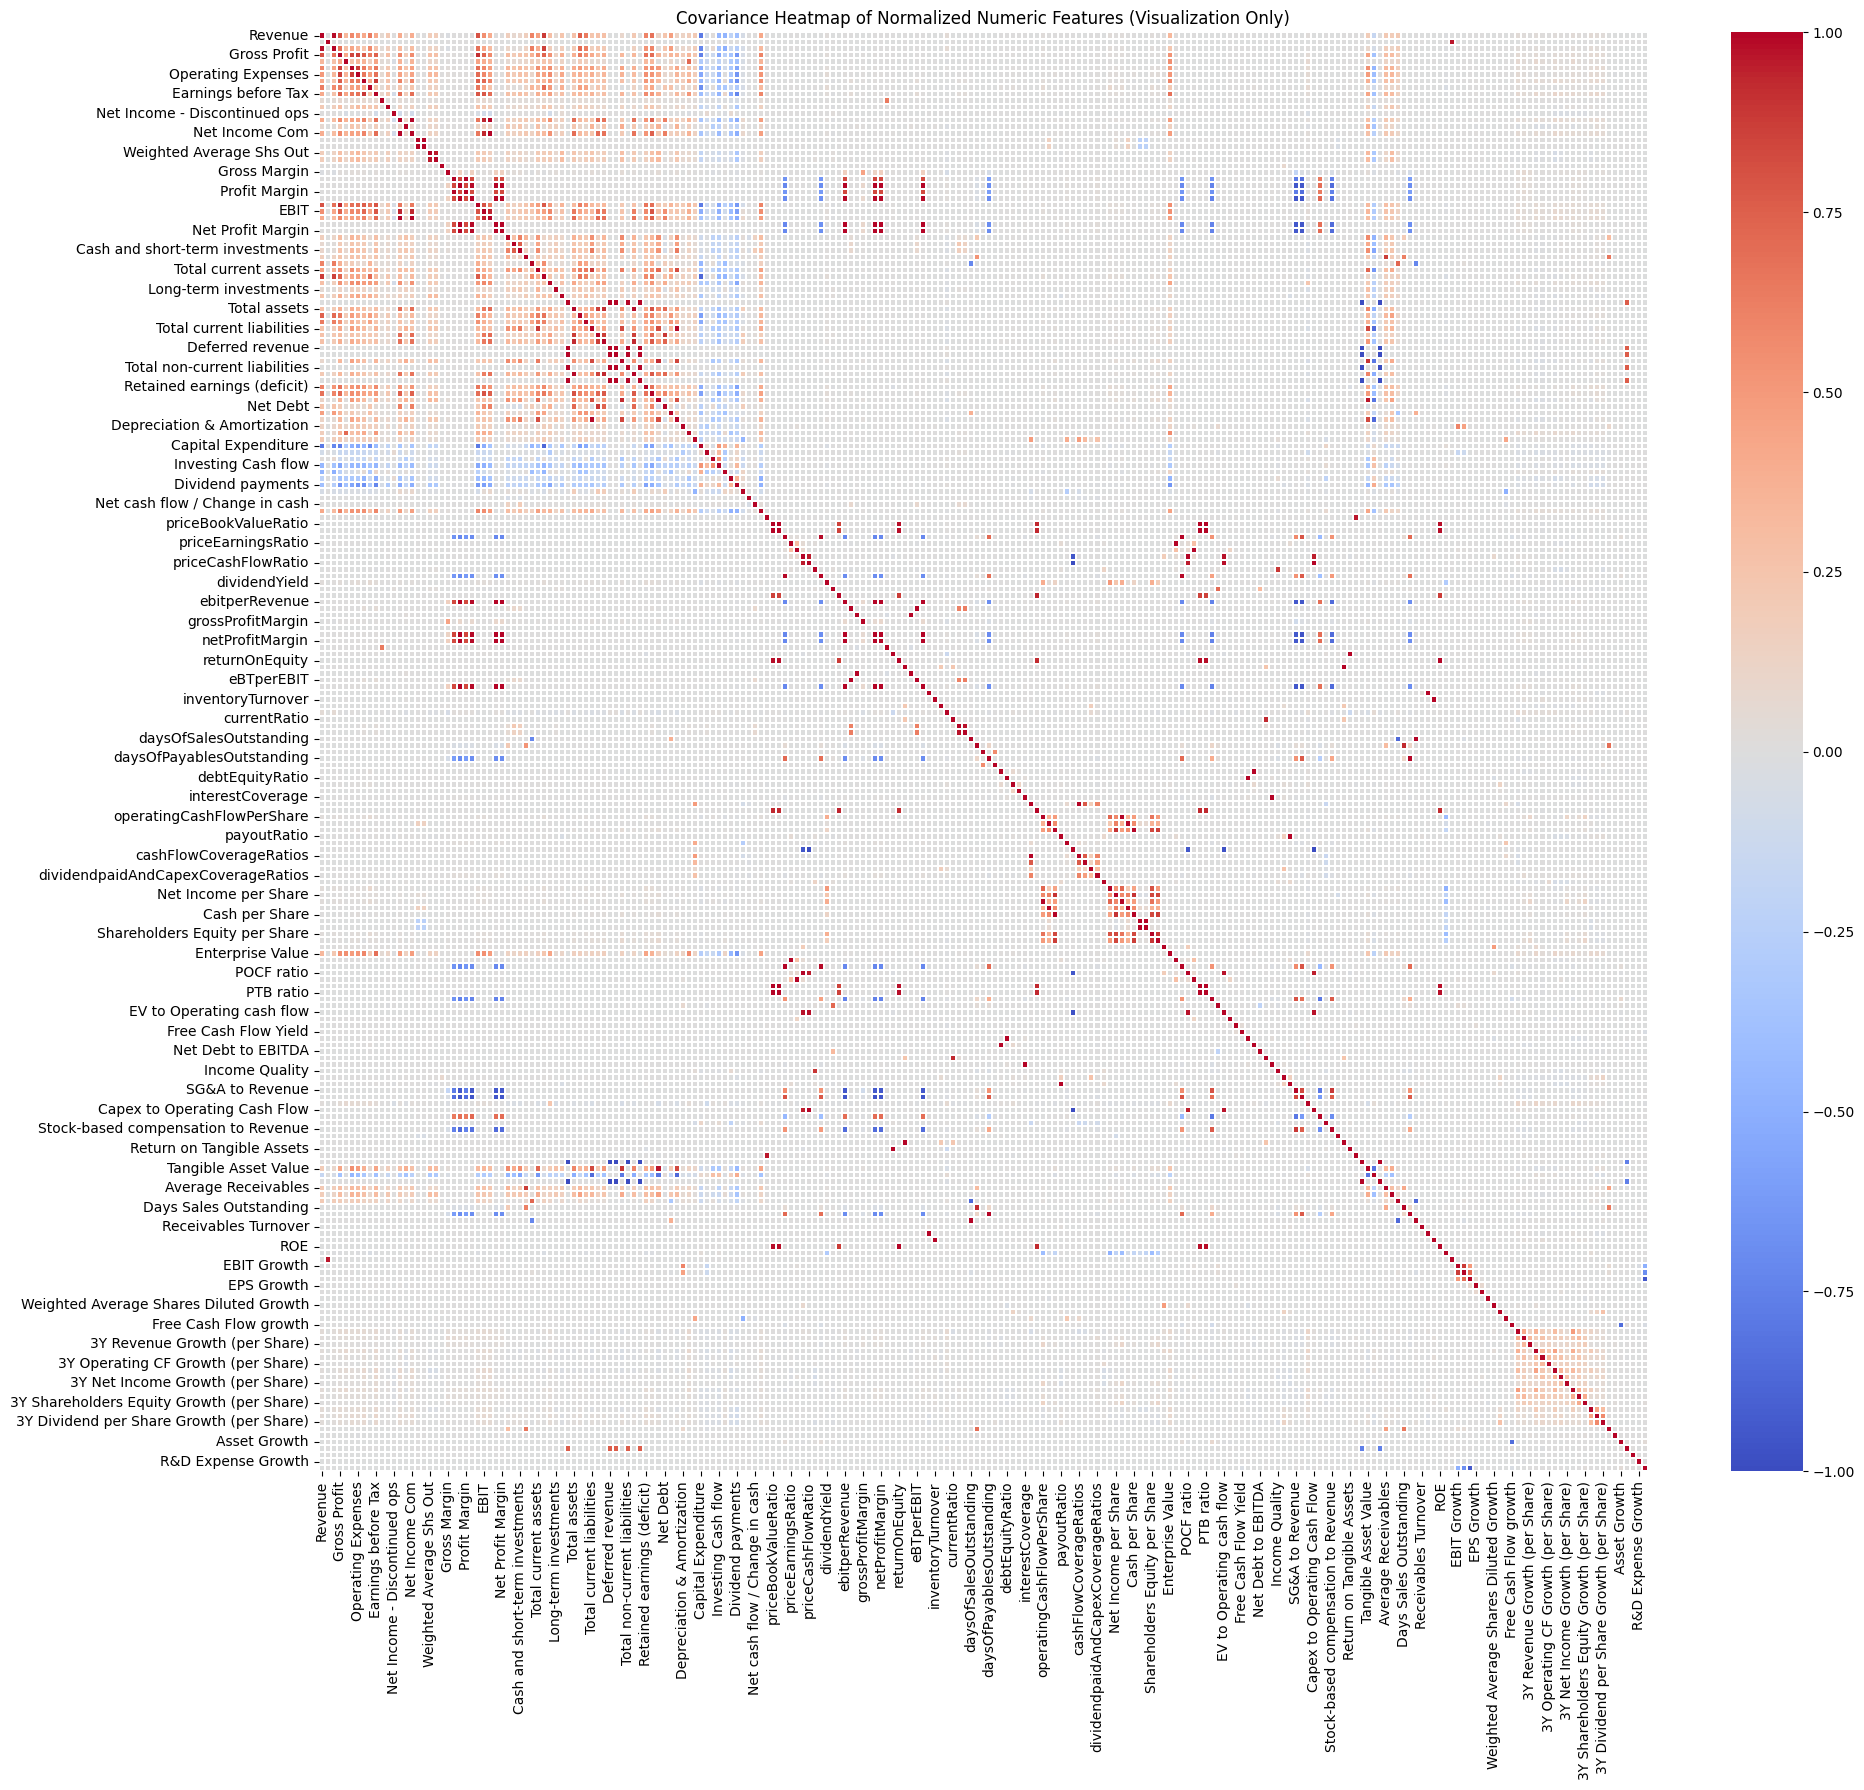

/var/folders/w0/w0zxtn3j7675228kq6fxwb2r0000gn/T/ipykernel_3040/1369356988.py:33: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(numeric_plot_df[col], fill=False, linewidth=1, alpha=0.5)


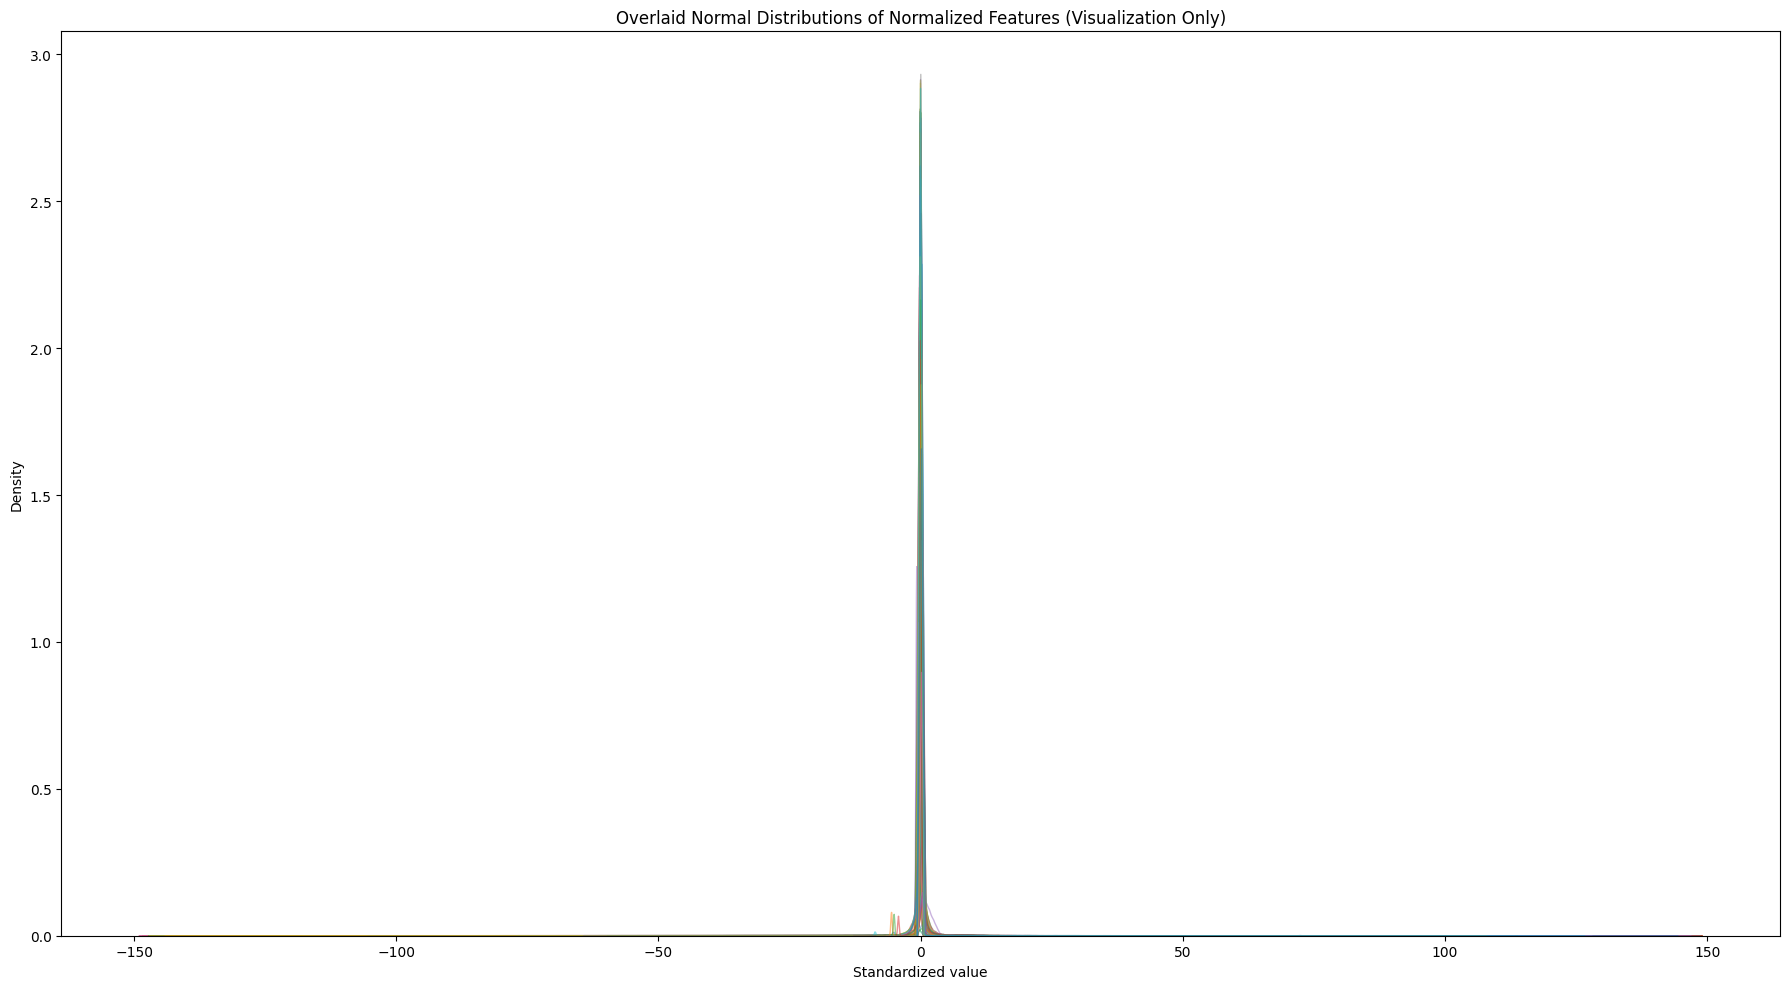

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Use only numeric feature columns, excluding target-like outputs and labels
exclude_cols = [col for col in df.columns if col.endswith(' PRICE VAR [%]') or col in ['Class', 'Sector']]
numeric_cols = [col for col in df.select_dtypes(include=['number']).columns if col not in exclude_cols]

# Build cleaned numeric dataset for modeling and a normalized copy for visualization only
numeric_df = df[numeric_cols].copy()
numeric_df = pd.DataFrame(
    SimpleImputer(strategy='mean').fit_transform(numeric_df),
    columns=numeric_cols
)
numeric_plot_df = pd.DataFrame(
    StandardScaler().fit_transform(numeric_df),
    columns=numeric_cols
)

# Covariance heatmap using normalized data for clearer visualization
cov_matrix = numeric_plot_df.cov()
plt.figure(figsize=(20, 18))
sns.heatmap(cov_matrix, cmap='coolwarm', center=0, linewidths=0.1)
plt.title('Covariance Heatmap of Normalized Numeric Features (Visualization Only)')
plt.tight_layout()
plt.show()

# Overlaid distribution plot for each normalized feature (plotting only)
plt.figure(figsize=(18, 10))
for col in numeric_plot_df.columns:
    sns.kdeplot(numeric_plot_df[col], fill=False, linewidth=1, alpha=0.5)

plt.title('Overlaid Normal Distributions of Normalized Features (Visualization Only)')
plt.xlabel('Standardized value')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

## Hyperparameter Tuning and Overfitting Check

This section tunes the XGBoost regressor with a grid search and evaluates it using MSE to check for overfitting.

Rows used for training: 19989 / 22077
Chosen model parameters:
{'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 5, 'subsample': 0.8, 'colsample_bytree': 0.8}
Train MSE: 9.1465
Test MSE: 6563.2199


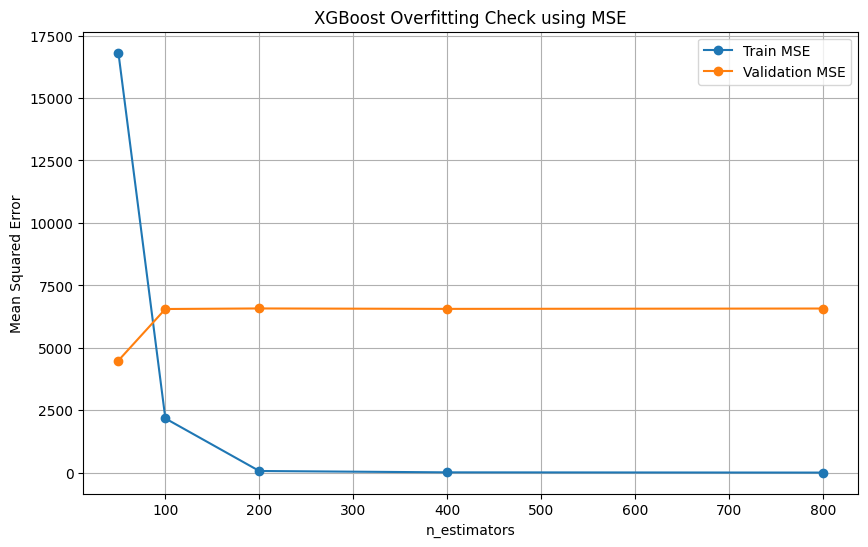

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

# Target to predict
TARGET = 'Revenue Growth'

# Exclude target and outcome-like columns
exclude_cols = [TARGET] + [col for col in df.columns if col.endswith(' PRICE VAR [%]')] + ['Class']
feature_df = df.drop(columns=[col for col in exclude_cols if col in df.columns], errors='ignore').copy()
y = df[TARGET].copy()
valid_mask = y.notna()
X = feature_df.loc[valid_mask].reset_index(drop=True)
y = y.loc[valid_mask].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Rows used for training: {len(X)} / {len(df)}')

# Identify numeric and categorical features
numeric_cols = X.select_dtypes(include=['number']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Preprocessing for numeric and categorical columns
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Use a sensible XGBoost configuration for a quick, stable baseline
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror',
    n_jobs=1
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model)
])

pipeline.fit(X_train, y_train)
train_pred = pipeline.predict(X_train)
test_pred = pipeline.predict(X_test)

train_mse = mean_squared_error(y_train, train_pred)
test_mse = mean_squared_error(y_test, test_pred)

print('Chosen model parameters:')
print({'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 5, 'subsample': 0.8, 'colsample_bytree': 0.8})
print(f'Train MSE: {train_mse:.4f}')
print(f'Test MSE: {test_mse:.4f}')

# Overfitting check: compare train and validation MSE across a few tree counts
n_estimators_to_test = [50, 100, 200, 400, 800]
train_mse_curve = []
test_mse_curve = []

for n in n_estimators_to_test:
    model_candidate = XGBRegressor(
        n_estimators=n,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        objective='reg:squarederror',
        n_jobs=1
    )
    candidate_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model_candidate)
    ])
    candidate_pipeline.fit(X_train, y_train)
    train_pred = candidate_pipeline.predict(X_train)
    test_pred = candidate_pipeline.predict(X_test)
    train_mse_curve.append(mean_squared_error(y_train, train_pred))
    test_mse_curve.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(10, 6))
plt.plot(n_estimators_to_test, train_mse_curve, marker='o', label='Train MSE')
plt.plot(n_estimators_to_test, test_mse_curve, marker='o', label='Validation MSE')
plt.xlabel('n_estimators')
plt.ylabel('Mean Squared Error')
plt.title('XGBoost Overfitting Check using MSE')
plt.legend()
plt.grid(True)
plt.show()